# RFI Analysis Workflow
Structured notebook for reusable Radio Frequency Interference (RFI) analysis.

This workflow is designed for datasets similar to SKAMPI observations.

Generated on: 2026-03-06T13:39:35 UTC


## 1. Imports

In [1]:
# import the libraries
import h5py
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import cm, colors as mcolors

import imageio # to collect frames and write them into an animated file.
import os
from PIL import Image
import io

import scienceplots
plt.style.use(['science', 'no-latex'])


from pybaselines import Baseline, utils 
from scipy.signal import find_peaks, peak_widths
from scipy.stats import skew, kurtosis, gaussian_kde
from astropy.stats import median_absolute_deviation as MAD
from astropy.modeling import models, fitting
from astropy.convolution import convolve_models

from concurrent.futures import ProcessPoolExecutor


## 2. Utility Functions

In [2]:
# baseline substraction
def base_correction(freq,power):
    """ 
    The function perform the baseline correction using the method: "Asymmetric Least Squer"

    Takes as entries:
    --------
    freq: array
    power: array

    Returns:
    ------
    The signal with the baseline corrected
    
    """

    # Step 1: define the baseli fitting
    baseline_fitter = Baseline(x_data=freq)
    bkg, params = baseline_fitter.asls(power, lam=1e7, p=0.02)

    # Step 2: Substract the baseline
    correct_baseline = power - bkg

    return correct_baseline

In [3]:
# quantify the outliers
def quantify_all_outliers(freq, power, peak_freqs, 
                           threshold=0.05, 
                           plot=True):
    """
    Quantify frequency range affected by each detected outlier.

    Parameters
    ----------
    freq : 1D array
        Frequency array (full spectrum).
    power : 1D array
        Detrended power spectrum at ONE time step.
    peak_freqs : list
        List of detected outlier peak frequencies (GHz).
    threshold : float
        Reference level to define rise/set.
    plot : bool
        If True, produce one plot per outlier.

    Returns
    -------
    results : list of dict
        One dictionary per outlier.
    """

    freq = np.asarray(freq)
    power = np.asarray(power)
    df = np.abs(freq[1] - freq[0])

    results_outliers = []

    for i, peak_f in enumerate(peak_freqs):

        # -------------------------------------------------
        # 1) Find closest index to detected peak frequency
        # -------------------------------------------------
        peak_index = np.argmin(np.abs(freq - peak_f))

        # -------------------------------------------------
        # 2) Walk LEFT until below threshold
        # -------------------------------------------------
        left_index = peak_index
        while left_index > 0 and power[left_index] > threshold:
            left_index -= 1

        start_freq = freq[left_index]

        # -------------------------------------------------
        # 3) Walk RIGHT until below threshold
        # -------------------------------------------------
        right_index = peak_index
        while right_index < len(power)-1 and power[right_index] > threshold:
            right_index += 1

        end_freq = freq[right_index]

        # -------------------------------------------------
        # 4) Compute bandwidth & channels
        # -------------------------------------------------
        bandwidth = end_freq - start_freq
        n_channels = int(np.round(bandwidth / df))

        peak_power = power[peak_index]

        result = {
            "peak_freq": freq[peak_index],
            "peak_power": peak_power,
            "start_freq": start_freq,
            "end_freq": end_freq,
            "bandwidth": bandwidth,
            "n_channels": n_channels,
        
            
        }

        results_outliers.append(result)

        # Print results
        print(f"\nOutlier {i+1}:")
        print(f"  Peak Frequency : {freq[peak_index]:.4f} GHz")
        print(f"  Peak Power     : {peak_power:.4f} dB")
        print(f"  Start Frequency: {start_freq:.4f} GHz")
        print(f"  End Frequency  : {end_freq:.4f} GHz")
        print(f"  Bandwidth      : {bandwidth:.4f} GHz")
        print(f"  Corrupted Ch.  : {n_channels} channels")

        # -------------------------------------------------
        # 5) Plot individual outlier
        # -------------------------------------------------
        if plot:
            # Add small padding for visualization
            pad = 10
            lo = max(left_index - pad, 0)
            hi = min(right_index + pad, len(freq)-1)

            plt.figure(figsize=(10,6))
            plt.plot(freq[lo:hi], power[lo:hi], '.', color='steelblue')
            plt.axvline(start_freq, color='green', linestyle='--', label='Start')
            plt.axvline(freq[peak_index], color='red', linestyle='-', label='Peak')
            plt.axvline(end_freq, color='orange', linestyle='--', label='End')
            plt.axhline(threshold, linestyle=':', color='black', label='Threshold = 0.05 dB')
            plt.xlabel("Frequency [GHz]", fontsize=17)
            plt.ylabel("Detrended Power [log(dB)]", fontsize=17)
            plt.title(f"Outlier {i+1} at {freq[peak_index]:.4f} GHz")
            plt.grid(True, linestyle='--', alpha=0.6)
            plt.legend(fontsize=12)
            # plt.show()



        #     plt.savefig(
        #     f"/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Detrending/SKAMPI_RFI_PIPELINE/outliers_{i+1}_at_{freq[peak_index]:.4f}.png",
        #     dpi=300,
        #     bbox_inches="tight"
        # )

        #     plt.savefig(
        #         f"/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Detrending/SKAMPI_RFI_PIPELINE/outliers_{i+1}_at_{freq[peak_index]:.4f}.pdf",
        #         dpi=300,
        #         bbox_inches="tight"
        #     )



    return results_outliers

In [4]:
# Define a function to quantify the RFI width
def quantify_RFI_width(freq, power):
    """
    Quantify how wide an RFI peak is in frequency.

    Parameters:
    freq : array
        Frequency array.
    power : array
        Power array with baseline corrected.
    mask : boolean array
        Mask to select the frequency window of interest.

    Returns:
    start_freq : float
        Frequency where power rises above threshold.
    end_freq : float
        Frequency where power falls below threshold.
    peak_freq : float
        Frequency of the peak power.
    peak_power : float
        Value of the peak power.
    """


    # --- 1) Find where power rises above zero ---
    threshold = 0.05  # small threshold 
    above_threshold = np.where(power > threshold)[0]

    if len(above_threshold) > 0.05:
        start_index = above_threshold[0]
        end_index = above_threshold[-1]
        start_freq = freq[start_index]
        end_freq = freq[end_index]
    else:
        start_freq = end_freq = np.nan
        print("No significant power detected in the masked range.")

    # --- 2) Find the frequency of the peak ---
    peak_index = np.argmax(power)
    peak_freq = freq[peak_index]
    peak_power = power[peak_index]


    print(f"Start Frequency: {start_freq:.4f} GHz")
    print(f"End Frequency: {end_freq:.4f} GHz")
    print(f"Peak Frequency: {peak_freq:.4f} GHz with Power: {peak_power:.4f} dB")


    # Number of channels corrupted.
    delta_frequency = (freq[1] - freq[0])  # spectral resolution / channel width
    chans = ((end_freq - start_freq) / delta_frequency)


    print(f'Number off corrupted channels: {chans: .1f}')


    # --- Plot results ---
    plt.figure(figsize=(12,6))
    plt.plot(freq, power, '.', color='steelblue', label='Data')
    plt.axvline(start_freq, color='green', linestyle='--', label='Start')
    plt.axvline(peak_freq, color='red', linestyle='-', label='Peak')
    plt.axvline(end_freq, color='orange', linestyle='--', label='End')
    plt.xlabel('Frequency [GHz]', fontsize=17)
    plt.ylabel('Power [dB]', fontsize=17)
    plt.legend(fontsize=14)
    plt.grid(linestyle='--')


    return start_freq, end_freq, peak_freq, peak_power


In [5]:
# process for a single time step

def process_single_time(i, frequency, spectrum, time_utc, sigma_value):
    """
    Process a single time step of the dynamic spectrum to detect RFI peaks.

    This function performs baseline correction on the spectrum for a given
    time index and then applies a peak detection algorithm to identify
    potential RFI signals based on a statistical threshold.

    Parameters
    ----------
    i : int
        Index of the time bin to be processed.

    frequency : numpy.ndarray
        1D array containing the frequency axis of the spectrum
        (typically in GHz).

    spectrum : numpy.ndarray
        2D array containing the dynamic spectrum with shape
        (time, frequency). Each row corresponds to a time step
        and each column corresponds to a frequency channel.

    time_utc : pandas.DatetimeIndex
        Array or index containing the observation timestamps
        corresponding to each row in `spectrum`.

    sigma_value : float
        Multiplicative factor used to define the peak detection
        threshold. The threshold is calculated as:

        threshold = MAD(det_spec) + sigma_value * std(det_spec)

    Returns
    -------
    dict
        Dictionary containing the processed results for the time step:

        - "time_index" : int
            Index of the processed time bin.

        - "time_label" : str
            Human-readable UTC time in HH:MM:SS format.

        - "det_spec" : numpy.ndarray
            Baseline-corrected spectrum for the given time step.

        - "peaks" : numpy.ndarray
            Indices of detected peaks in the corrected spectrum.

        - "peak_freqs" : numpy.ndarray
            Frequencies corresponding to the detected peaks.

        - "threshold" : float
            Detection threshold used for the peak identification.

    Notes
    -----
    The function applies the following processing steps:

    1. Baseline correction using `base_correction()`.
    2. Threshold estimation using MAD and standard deviation.
    3. Peak detection using `scipy.signal.find_peaks`.

    Example
    -------
    >>> result = process_single_time(
    ...     i=10,
    ...     frequency=frequency,
    ...     spectrum=spectrum,
    ...     time_utc=time_utc,
    ...     sigma_value=5
    ... )

    >>> print(result["peak_freqs"])
    array([2.4831, 2.4834])
    """

    det_spec_itime = base_correction(frequency, spectrum[i, :])
    threshold = MAD(det_spec_itime) + sigma_value * np.std(det_spec_itime)
    peaks, properties = find_peaks(det_spec_itime,
                                   height=threshold,
                                   prominence=1.5,
                                   distance=100
                                   )
    peak_freqs = frequency[peaks]


    return {
        "time_index": i,
        "time_label": time_utc[i].strftime("%H:%M:%S"),
        "det_spec": det_spec_itime,
        "peaks": peaks,
        "peak_freqs": peak_freqs,
        "threshold": threshold
    }

# Run in parallel for all target times

def process_all_times(frequency, spectrum,time_utc, time_step, sigma_value, n_workers=None):
    """
    Process multiple time steps of a dynamic spectrum in parallel.

    This function selects time bins at regular intervals and processes
    each selected time step using the `process_single_time` function.
    Parallel execution is used to accelerate the computation.

    Parameters
    ----------
    frequency : numpy.ndarray
        1D array containing the frequency axis of the spectrum.

    spectrum : numpy.ndarray
        2D dynamic spectrum with shape (time, frequency).

    time_utc : pandas.DatetimeIndex
        Array containing the observation timestamps corresponding
        to each time bin in `spectrum`.

    time_step : int
        Time interval (in seconds) between processed time bins.
        For example, `time_step=30` processes one spectrum every
        30 seconds.

    sigma_value : float
        Sigma multiplier used to compute the detection threshold
        for peak identification.

    n_workers : int, optional
        Number of parallel processes used by the `ProcessPoolExecutor`.
        If None, Python automatically selects the number of available CPUs.

    Returns
    -------
    list of dict
        A list where each element is the output dictionary returned
        by `process_single_time()` for a specific time bin.

        Each dictionary contains detected peaks, frequencies,
        thresholds, and the corrected spectrum for that time step.

    Notes
    -----
    The workflow of this function is:

    1. Generate target timestamps using `pandas.date_range`.
    2. Map those timestamps to the closest indices in `time_utc`.
    3. Process each selected time bin in parallel using
       `ProcessPoolExecutor`.
    4. Collect and return the results.

    Example
    -------
    >>> results = process_all_times(
    ...     frequency=frequency,
    ...     spectrum=spectrum,
    ...     time_utc=time_utc,
    ...     time_step=30,
    ...     sigma_value=5,
    ...     n_workers=8
    ... )

    >>> print(len(results))
    120

    >>> print(results[0]["peak_freqs"])
    array([2.4831, 2.4834])
    """


    target_times = pd.date_range(
        start=time_utc[0],
        end=time_utc[-1],
        freq=f'{time_step}s'
    )

    itime_target = time_utc.get_indexer(target_times, method='nearest')

    with ProcessPoolExecutor(max_workers=n_workers) as executor:

        features = [
            executor.submit(process_single_time, i, frequency, spectrum, time_utc, sigma_value)
            for i in itime_target
        ]
        results_sing_proc = [f.result() for f in features]


    return results_sing_proc



In [6]:
# Function to compute RFI percentage per band for the whole observation
def rfi_percentage_per_band(freq, results_all_times, rfi_bands):
    """
    Compute the RFI occupancy percentage for each predefined frequency band
    over the entire observation.

    This function evaluates how much of each RFI band is affected by
    radio-frequency interference (RFI) during the observation. The method
    iterates through all time steps, determines the corrupted frequency
    ranges produced by detected outliers, and counts how many channels
    within each band were contaminated.

    The final percentage represents the fraction of samples in a given
    band that were corrupted by RFI relative to all possible samples
    within that band during the observation.

    Parameters
    ----------
    freq : array-like
        1D array containing the frequency axis of the spectrum in GHz.
        Each element represents the central frequency of a spectral
        channel.

    results_all_times : list of dict
        List containing the analysis results for each time step of the
        observation. Each dictionary typically includes:
            - 'time_index' : index of the time bin
            - 'det_spec'   : detrended power spectrum at that time
            - 'peak_freqs' : list of detected RFI peak frequencies (GHz)

    rfi_bands : dict
        Dictionary defining the known RFI frequency bands. The format is:

        {
            "Band name": (start_frequency, end_frequency)
        }

        Example:
        {
            "Wi-Fi / Bluetooth (ISM)": (2.40, 2.483),
            "LTE / 5G (2600 band)": (2.50, 2.69)
        }

    Returns
    -------
    band_results : dict
        Dictionary containing the RFI occupancy percentage for each band.

        Example output:
        {
            "Cellular GSM Downlink": 2.4,
            "Wi-Fi / Bluetooth (ISM)": 28.7,
            "LTE / 5G (2600 band)": 6.1
        }

        Values represent the percentage (%) of the band affected by RFI
        across the entire observation.

    Notes
    -----
    - The algorithm avoids double-counting overlapping peaks by building
      a boolean mask of corrupted channels.
    - The occupancy percentage is computed as:

      RFI (%) = corrupted_samples / total_samples_in_band × 100

    - The total samples in a band are defined as:

      total_samples = (number_of_channels_in_band × number_of_time_steps)

    - This metric is commonly referred to as **RFI occupancy** in
      radio astronomy and is frequently used to characterize the
      interference environment of radio telescopes.

    Applications
    ------------
    This method is useful for:

    - Quantifying RFI contamination in radio telescope observations
    - Identifying heavily polluted communication bands
    - Producing RFI environment reports
    - Comparing interference levels between observations

    Examples
    --------
    >>> band_stats = rfi_percentage_per_band(
    ...     frequency,
    ...     results_all_times,
    ...     rfi_bands
    ... )

    >>> print(band_stats["Wi-Fi / Bluetooth (ISM)"])
    28.9
    """

    freq = np.asarray(freq)
    n_time = len(results_all_times)

    band_results = {}

    for band_name, (band_start, band_end) in rfi_bands.items():

        # Identify frequency channels belonging to the band
        band_mask = (freq >= band_start) & (freq <= band_end)
        band_indices = np.where(band_mask)[0]

        # Total possible samples in this band
        total_band_points = len(band_indices) * n_time

        corrupted_points = 0

        for res in results_all_times:

            rest = res['det_spec']

            # Detect corrupted ranges for this time step
            results_outliers = quantify_all_outliers(
                freq,
                rest,
                res['peak_freqs'],
                plot=False
            )

            # Build mask of corrupted channels
            corrupted_mask = np.zeros(len(freq), dtype=bool)

            for out in results_outliers:

                start = out["start_freq"]
                end = out["end_freq"]

                mask = (freq >= start) & (freq <= end)
                corrupted_mask |= mask

            # Count corrupted channels inside this band
            corrupted_points += np.sum(corrupted_mask[band_indices])

        # Compute occupancy percentage
        percent = 100 * corrupted_points / total_band_points

        band_results[band_name] = percent

        print(f"\n{band_name}")
        print(f"Band range        : {band_start:.3f} - {band_end:.3f} GHz")
        print(f"Corrupted points  : {corrupted_points}")
        print(f"Total band points : {total_band_points}")
        print(f"RFI occupancy     : {percent:.2f} %")

    return band_results



# test 

def rfi_percentage_per_band_test(freq, results_all_times, rfi_bands):
     
    """
    Calculate the spectral RFI occupancy for each frequency band.

    This function estimates the percentage of frequency-time samples within
    each predefined frequency band that are affected by detected RFI. For
    every time step, the detected spectral peaks are used to identify
    corrupted frequency ranges. The number of corrupted frequency channels
    falling within each band is then accumulated across all time steps.

    Frequency bands whose names contain ``"Gap"`` or ``"Overlap"`` are
    classified as ``"TRANSITION"`` bands, while all other bands are classified
    as ``"ALLOCATED"`` bands.

    Parameters
    ----------
    freq : array-like
        One-dimensional frequency array corresponding to the spectral
        channels. Frequencies must be expressed in GHz and must have the
        same length as the spectral data in ``results_all_times``.

    results_all_times : list of dict
        Results for each time step. Each dictionary is expected to contain:

        - ``'det_spec'`` : array-like
            Detrended or corrected spectrum for the corresponding time step.
        - ``'peak_freqs'`` : array-like
            Frequencies of the detected RFI peaks.

        The dictionaries are passed to ``quantify_all_outliers()`` to
        determine the frequency ranges affected by RFI.

    rfi_bands : dict
        Dictionary defining the frequency bands to be evaluated. Each key
        represents a band name and each value must be a two-element tuple
        containing the lower and upper frequency limits in GHz.

        Example
        -------
        {
            "GSM": (1.80, 1.88),
            "UMTS": (2.11, 2.17),
            "ISM": (2.40, 2.483),
            "Gap": (2.483, 2.500)
        }

        Bands containing ``"Gap"`` or ``"Overlap"`` in their names are
        classified as transition regions.

    Returns
    -------
    band_results : dict
        Dictionary containing the RFI occupancy percentage for each
        frequency band.

        The keys correspond to the band names in ``rfi_bands`` and the
        values are the percentage of frequency-time samples identified as
        corrupted by RFI.

    Notes
    -----
    The RFI occupancy is calculated as

    .. math::

        \\mathrm{RFI\\ Occupancy}(\\%) =
        \\frac{N_{\\mathrm{corrupted}}}
        {N_{\\mathrm{channels}} \\times N_{\\mathrm{time}}}
        \\times 100.

    Here, ``N_corrupted`` is the total number of corrupted frequency-time
    samples detected within the band, ``N_channels`` is the number of
    frequency channels contained in the band, and ``N_time`` is the number
    of analysed time steps.

    For each time step, the function:

    1. Uses ``quantify_all_outliers()`` to determine the start and end
       frequencies of detected RFI features.
    2. Converts these frequency ranges into a Boolean mask over the
       frequency array.
    3. Counts the corrupted channels that fall inside each frequency band.
    4. Accumulates the corrupted channels over all time steps.
    5. Converts the accumulated count into an RFI occupancy percentage.

    The resulting percentage therefore represents both the **spectral
    extent** and **temporal persistence** of the detected RFI.

    Examples
    --------
    >>> percentages = rfi_percentage_per_band_test(
    ...     freq,
    ...     results_all_times,
    ...     rfi_bands
    ... )
    >>> print(percentages["GSM"])
    12.45

    See Also
    --------
    quantify_all_outliers : Determines the frequency extent of detected
        spectral outliers.
    """

    freq = np.asarray(freq)
    n_time = len(results_all_times)

    band_results = {}

    for band_name, (band_start, band_end) in rfi_bands.items():

        # Identify frequency channels belonging to the band
        band_mask = (freq >= band_start) & (freq <= band_end)
        band_indices = np.where(band_mask)[0]

        # Total possible samples in this band
        total_band_points = len(band_indices) * n_time

        corrupted_points = 0

        for res in results_all_times:

            rest = res['det_spec']

            # Detect corrupted ranges for this time step
            results_outliers = quantify_all_outliers(
                freq,
                rest,
                res['peak_freqs'],
                plot=False
            )

            # Build mask of corrupted channels
            corrupted_mask = np.zeros(len(freq), dtype=bool)

            for out in results_outliers:

                start = out["start_freq"]
                end = out["end_freq"]

                mask = (freq >= start) & (freq <= end)
                corrupted_mask |= mask

            # Count corrupted channels inside this band
            corrupted_points += np.sum(corrupted_mask[band_indices])

        # Compute occupancy percentage
        percent = 100 * corrupted_points / total_band_points

        band_results[band_name] = percent

        # 🔹 NEW: classify band type
        if "Gap" in band_name or "Overlap" in band_name:
            band_type = "TRANSITION"
        else:
            band_type = "ALLOCATED"

        print(f"\n{band_name} [{band_type}]")
        print(f"Band range        : {band_start:.3f} - {band_end:.3f} GHz")
        print(f"Corrupted points  : {corrupted_points}")
        print(f"Total band points : {total_band_points}")
        print(f"RFI occupancy     : {percent:.2f} %")
    return band_results







def rfi_percentage_per_band_low(freq, results_low_all_times, rfi_bands):
    """
    Same as rfi_percentage_per_band, but operates on results_low_all_times,
    where outliers have already been pre-computed and stored under the
    'outliers' key in each time-bin dictionary.
    """

    freq = np.asarray(freq)
    n_time = len(results_low_all_times)

    band_results = {}

    for band_name, (band_start, band_end) in rfi_bands.items():

        band_mask = (freq >= band_start) & (freq <= band_end)
        band_indices = np.where(band_mask)[0]
        total_band_points = len(band_indices) * n_time

        corrupted_points = 0

        for res in results_low_all_times:

            # Use pre-computed outliers instead of calling quantify_all_outliers
            results_outliers = res['outliers']

            corrupted_mask = np.zeros(len(freq), dtype=bool)

            for out in results_outliers:
                start = out["start_freq"]
                end   = out["end_freq"]
                corrupted_mask |= (freq >= start) & (freq <= end)

            corrupted_points += np.sum(corrupted_mask[band_indices])

        percent = 100 * corrupted_points / total_band_points
        band_results[band_name] = percent

        print(f"\n{band_name}")
        print(f"Band range        : {band_start:.3f} - {band_end:.3f} GHz")
        print(f"Corrupted points  : {corrupted_points}")
        print(f"Total band points : {total_band_points}")
        print(f"RFI occupancy     : {percent:.2f} %")

    return band_results




## 3. Load Dataset and convert to xarray

# Load the data

Define parameters here so the notebook can easily be reused with other datasets.

EDD_2023-03-11T14_58_01.567317UTC_ErQFG.hdf5

EDD_2023-04-18T18_40_20.581801UTC_NkSzr.hdf5 

EDD_2023-07-14T07_22_49.024178UTC_neSzZ.hdf5 

EDD_2023-08-07T15_07_54.890197UTC_tnEks.hdf5


In [7]:
# DATA
filename = "EDD_2023-03-11T14_58_01.567317UTC_ErQFG.hdf5"
path = f'/home/chavango/Master/DATA/SKAMPI_data/{filename}'

# Create a dictionary to store the plots
dirname = filename.split('.')[0]

to_save = True 

In [8]:
# Convert to xarray data set
groups = [
    "scan/000/P1_ND0",
    "scan/000/P1_ND1",
    "scan/001/P0_ND0",
    "scan/001/P0_ND1",
    "scan/001/P1_ND0",
    "scan/001/P1_ND1"
]

datasets = {}

with h5py.File(path, 'r') as f:
    for g in groups:

        spectrum  = f[f"{g}/spectrum"][30:,1700:-60]
        frequency = f[f"{g}/frequency"][1700:-60] / 1e9
        time      = f[f"{g}/timestamp"][30:,0]
        integration_time = f[f"{g}/integration_time"][30:,0]

        ds = xr.Dataset(
            {"spectrum": (("time","frequency"), spectrum),
             "integration_time": (("time"), integration_time)},
            coords={"time": time, "frequency": frequency}
        )

        datasets[g] = ds

In [9]:
# spectrum_data = obsfile[d.replace('timestamp','')+'spectrum'][:]
# integration_time_data = obsfile[d.replace('timestamp','integration_time')][:].flatten()
# waterfall_data  = spectrum_data / integration_time_data[:,np.newaxis]



In [10]:
datasets.keys()

dict_keys(['scan/000/P1_ND0', 'scan/000/P1_ND1', 'scan/001/P0_ND0', 'scan/001/P0_ND1', 'scan/001/P1_ND0', 'scan/001/P1_ND1'])

In [11]:
ds

<xarray.Dataset> Size: 163MB
Dimensions:           (time: 636, frequency: 63777)
Coordinates:
  * time              (time) float64 5kB 1.679e+09 1.679e+09 ... 1.679e+09
  * frequency         (frequency) float64 510kB 1.795 1.795 ... 3.498 3.498
Data variables:
    spectrum          (time, frequency) float32 162MB 6.592e+10 ... 1.672e+09
    integration_time  (time) float64 5kB 0.0396 0.0375 0.0375 ... 0.03926 0.0375

In [12]:
# select a scan
scan = 'scan/000/P1_ND0'
# Extract scan name
scan_name = scan.replace('/', '_')

data = datasets[scan]
data

<xarray.Dataset> Size: 162MB
Dimensions:           (time: 634, frequency: 63777)
Coordinates:
  * time              (time) float64 5kB 1.679e+09 1.679e+09 ... 1.679e+09
  * frequency         (frequency) float64 510kB 1.795 1.795 ... 3.498 3.498
Data variables:
    spectrum          (time, frequency) float32 162MB 1.744e+11 ... 4.159e+09
    integration_time  (time) float64 5kB 0.1158 0.1129 0.1159 ... 0.1155 0.1159

## 5. Convert the variables

In [13]:
# define the variables
spectra = data['spectrum'].values
integration_time = data['integration_time'].values
spectrum = spectra / integration_time[:, np.newaxis]
frequency_ghz = data['frequency'].values 
time = data['time'].values





# Spectrum to dB
spectrum_db = (10*np.log10(spectrum**2))


# Time to UTC
time_utc = pd.to_datetime(time, unit='s', origin='unix', utc=True)


In [14]:
# frequency resolution
freq_resol = frequency_ghz[1] - frequency_ghz[0]
freq_resol

np.float64(2.6702880859375e-05)

In [15]:
frequency_resolution = np.mean(np.diff(frequency_ghz))

print(f"Frequency resolution = {frequency_resolution:.6e} GHz")
print(f"Frequency resolution = {frequency_resolution*1e6:.2f} kHz")

Frequency resolution = 2.670288e-05 GHz
Frequency resolution = 26.70 kHz


## 6. Dynamic Spectrum

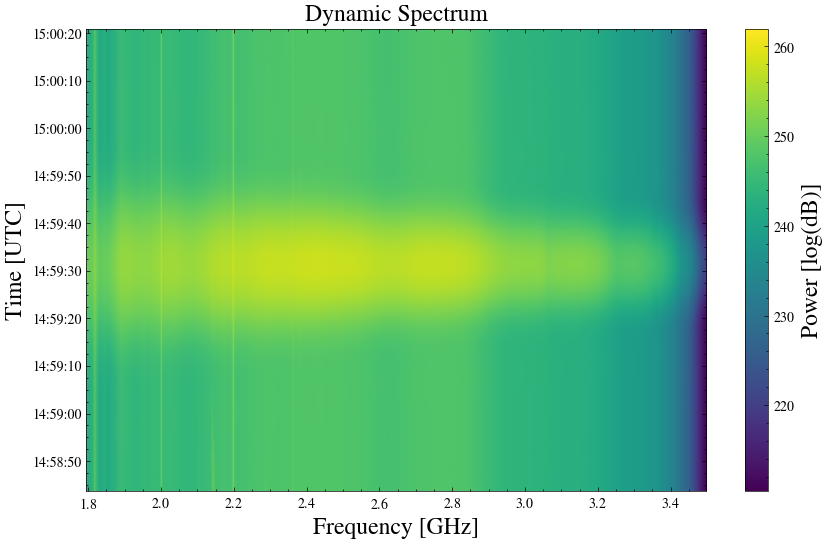

In [16]:
plt.figure(figsize=(10,6))

im = plt.imshow(
    spectrum_db,
    aspect='auto',
    extent=[frequency_ghz[0], frequency_ghz[-1], time_utc[0], time_utc[-1]],
    origin='lower',
    cmap='viridis'
)



cbar = plt.colorbar(im)
cbar.set_label(label='Power [log(dB)]', fontsize=17)

plt.xlabel('Frequency [GHz]', fontsize=17)
plt.ylabel('Time [UTC]', fontsize=17)
plt.title('Dynamic Spectrum', fontsize=17)


# create full path
full_path = os.path.join(dirname, scan_name)
# create the directory if they don't exist
os.makedirs(full_path, exist_ok=True)

plot_png = os.path.join(full_path, f'dynamic_spectrum{scan_name}.png')
plot_pdf = os.path.join(full_path, f'dynamic_spectrum{scan_name}.pdf')
plt.savefig(plot_png, dpi=300, bbox_inches='tight')
plt.savefig(plot_pdf, dpi=300, bbox_inches='tight')

## 7. Evaluate the power spectrum for different time bin

* Peak detection with treshold of MAD + 3*STD

Peaks detected at [14:58:43]: ['1.8196', '2.0028', '2.1063', '2.1459', '2.1999', '2.3627', '2.4920'] GHz


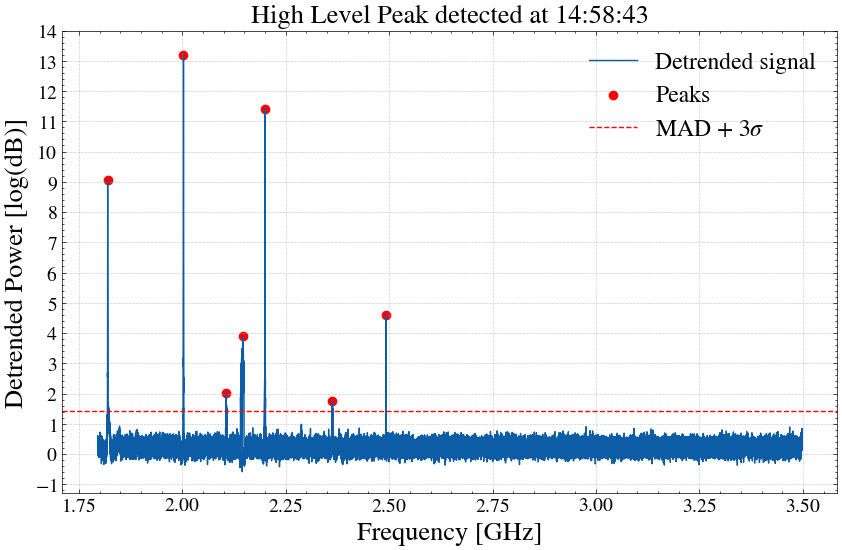

In [17]:

# Define your desired time step in seconds
time_step = 15  

# Select time indices with approximately 15-second spacing
target_times = pd.date_range(start=time_utc[0], end=time_utc[-1], freq=f'{time_step}s')

# Find nearest indices in your actual time_utc
itime_target = time_utc.get_indexer(target_times, method='nearest')


for i in itime_target:
    # Detrend / baseline correct the spectrum at this time
    det_spec_itime = base_correction(frequency_ghz, spectrum_db[i, :])


    sigma_value_high = 3
    # Detect peaks
    threshold = MAD(det_spec_itime) + sigma_value_high * np.std(det_spec_itime)
    peaks, properties = find_peaks(det_spec_itime,
                                   height=threshold,
                                   prominence=1.5,
                                   distance=100
                                   )

    # Plot
    plt.figure(figsize=(10, 6))
    plt.plot(frequency_ghz, det_spec_itime, label=f'Detrended signal')
    plt.scatter(frequency_ghz[peaks], det_spec_itime[peaks], color='red', label='Peaks')
    plt.axhline(y=threshold, color='red', linestyle='--', label=f'MAD + {sigma_value_high}$σ$')

    plt.title(f'High Level Peak detected at {time_utc[i].strftime("%H:%M:%S")}', fontsize=19)
    plt.xlabel('Frequency [GHz]',fontsize=19)
    plt.ylabel('Detrended Power [log(dB)]',fontsize=19)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend(fontsize=17)

    yticks=np.arange(-1, 15)
    plt.yticks(yticks)
    plt.yticks(fontsize=14)
    plt.xticks(fontsize=14)


    # --- Print detected peak frequencies ---
    formatted_freqs = [f"{f:.4f}" for f in frequency[peaks]]

    print(f"Peaks detected at [{time_utc[i].strftime('%H:%M:%S')}]: {formatted_freqs} GHz")

    plt.show()
    

    # # create full path
    # full_path = os.path.join(dirname, scan_name)
    # # create the directory if they don't exist
    # os.makedirs(full_path, exist_ok=True)

    # plot_path = os.path.join(full_path, f'dynamic_spectrum{scan_name}.png')
    # plt.savefig(plot_path, dpi=300)


    break

## Save the peaks as an inimation

In [18]:
# # save the plots as  gif animation
# filenames = []
# for i in itime_target:
#     # Detrend / baseline correct the spectrum at this time
#     det_spec_itime = base_correction(frequency, spectrum[i, :])


#     # Detect peaks
#     threshold = MAD(det_spec_itime) + 3 * np.std(det_spec_itime)
#     peaks, properties = find_peaks(det_spec_itime,
#                                    height=threshold,
#                                    prominence=1.5,
#                                    distance=100
#                                    )

#     # Plot
#     plt.figure(figsize=(10, 6))
#     plt.plot(frequency, det_spec_itime, label=f'Detrended signal')
#     plt.scatter(frequency[peaks], det_spec_itime[peaks], color='red', label='Peaks')
#     plt.axhline(y=threshold, color='red', linestyle='--', label='Mean + $3σ$')

#     plt.title(f'High Level Peak detected at {time_utc[i].strftime("%H:%M:%S")}', fontsize=16)
#     plt.xlabel('Frequency [GHz]',fontsize=16)
#     plt.ylabel('Power [log(dB)]',fontsize=16)
#     plt.grid(True, linestyle='--', alpha=0.6)
#     plt.legend(fontsize=12)

#     #plt.xlim(2.358,2.365)



#     # --- Print detected peak frequencies ---
#     formatted_freqs = [f"{f:.4f}" for f in frequency[peaks]]

#     print(f"Peaks detected at [{time_utc[i].strftime('%H:%M:%S')}]: {formatted_freqs} GHz")

#     filename = f"det_asls_plots/peak_{time_utc[i].strftime('%H%M%S')}.png"    
#     filenames.append(filename)
#     plt.savefig(filename, dpi=120, bbox_inches='tight')

# for filename in filenames:
#     img = imageio.imread(filename)
#     print(filename, img.shape)


# # # Clean up PNG files
# # for filename in filenames:
# #     os.remove(filename)

# # print("GIF saved successfully!")

In [19]:

# frames = []

# all_det = []

# for i in itime_target:
#     det = base_correction(frequency, spectrum[i, :])
#     all_det.append(det)

# all_det = np.array(all_det)

# global_min = np.min(all_det)
# global_max = np.max(all_det)

# for i in itime_target:

#     det_spec_itime = base_correction(frequency, spectrum[i, :])

#     threshold = MAD(det_spec_itime) + 3 * np.std(det_spec_itime)
#     peaks, _ = find_peaks(det_spec_itime, height=threshold)

#     fig, ax = plt.subplots(figsize=(10, 6), dpi=120)

#     ax.plot(frequency, det_spec_itime, label=f'Detrended signal')
#     ax.scatter(frequency[peaks], det_spec_itime[peaks], color='red', label='Peaks')
#     ax.axhline(y=threshold, color='red', linestyle='--', label='Mean + $3σ$')

#     ax.set_xlim(frequency.min(), frequency.max())
#     ax.set_ylim(global_min, global_max)
#     ax.grid(True, linestyle='--', alpha=0.6)
#     ax.set_title(f'High Level Peak detected at {time_utc[i].strftime("%H:%M:%S")}', fontsize=16)
#     ax.set_xlabel('Frequency [GHz]',fontsize=16)
#     ax.set_ylabel('Power [log(dB)]',fontsize=16)
#     ax.legend(fontsize=12)

#     buf = io.BytesIO()
#     plt.savefig(buf, format="png", dpi=120)
#     plt.close(fig)

#     buf.seek(0)
#     img = Image.open(buf).convert("RGB")
#     frames.append(np.array(img))


# imageio.mimsave(
#     f'det_asls_plots/rfi_peaks_{time_utc[0].strftime("%Y-%m-%d")}.gif',
#     frames,
#     duration=5.0
# )


### Analyse the band corrputed by high level peaks

Peaks detected at [14:58:43]: ['1.8196', '2.0028', '2.1063', '2.1459', '2.1999', '2.3627', '2.4920'] GHz


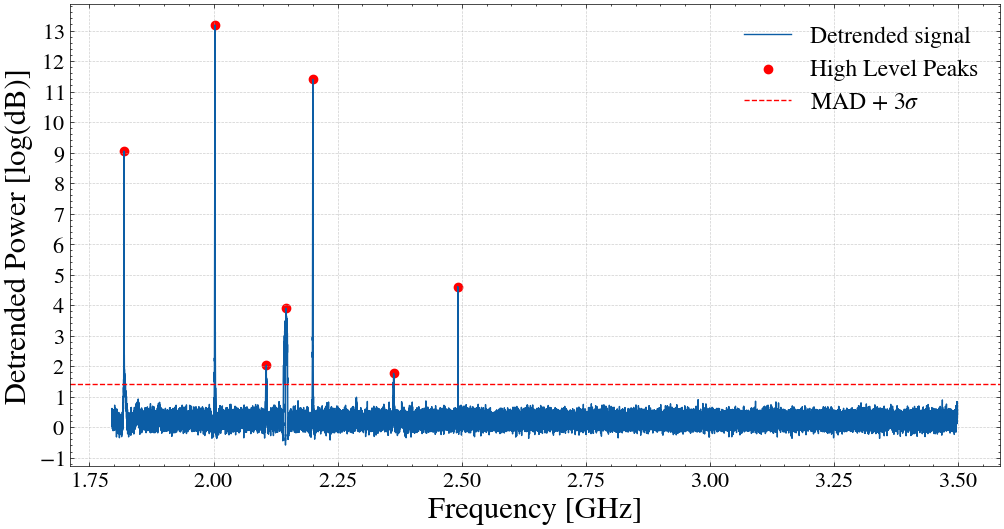

In [20]:
# run for a single time step to test

target_high = process_single_time(itime_target[0], frequency_ghz, spectrum_db, time_utc, sigma_value=sigma_value_high)

# --- Print detected peak frequencies ---
formatted_freqs = [f"{f:.4f}" for f in target_high['peak_freqs']]

print(f"Peaks detected at [{time_utc[target_high['time_index']].strftime('%H:%M:%S')}]: {formatted_freqs} GHz")


plt.figure(figsize=(12, 6))
plt.plot(frequency_ghz, target_high['det_spec'], label=f'Detrended signal')
plt.scatter(frequency_ghz[target_high['peaks']], target_high['det_spec'][target_high['peaks']], color='red', label='High Level Peaks')
plt.axhline(y=target_high['threshold'], color='red', linestyle='--', label=f'MAD + {sigma_value_high}$σ$')
#plt.title(f'High Level Peak detected at {target_high["time_label"]}', fontsize=19)
plt.xlabel('Frequency [GHz]',fontsize=22)
plt.ylabel('Detrended Power [log(dB)]',fontsize=22)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=17)

yticks=np.arange(-1, 14, 1)
plt.yticks(yticks)
plt.yticks(fontsize=16)
plt.xticks(fontsize=16)

plt.savefig('/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Detrending/SKAMPI_RFI_PIPELINE/high_level_peak_plot.png', dpi=300, bbox_inches='tight')
plt.savefig('/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Detrending/SKAMPI_RFI_PIPELINE/high_level_peak_plot.pdf', dpi=300, bbox_inches='tight')


plt.show()

In [21]:
target_high

{'time_index': np.int64(0),
 'time_label': '14:58:43',
 'det_spec': array([0.21815196, 0.61350244, 0.30573327, ..., 0.6640858 , 0.39667074,
        0.56529532], shape=(63777,)),
 'peaks': array([  908,  7768, 11645, 13125, 15149, 21246, 26088]),
 'peak_freqs': array([1.81962776, 2.00280952, 2.10633659, 2.14585686, 2.19990349,
        2.36271095, 2.4920063 ]),
 'threshold': np.float64(1.4186465846204004)}

Peaks detected at [14:58:43]: ['1.8196', '2.0028', '2.1063', '2.1459', '2.1999', '2.3627', '2.4920'] GHz


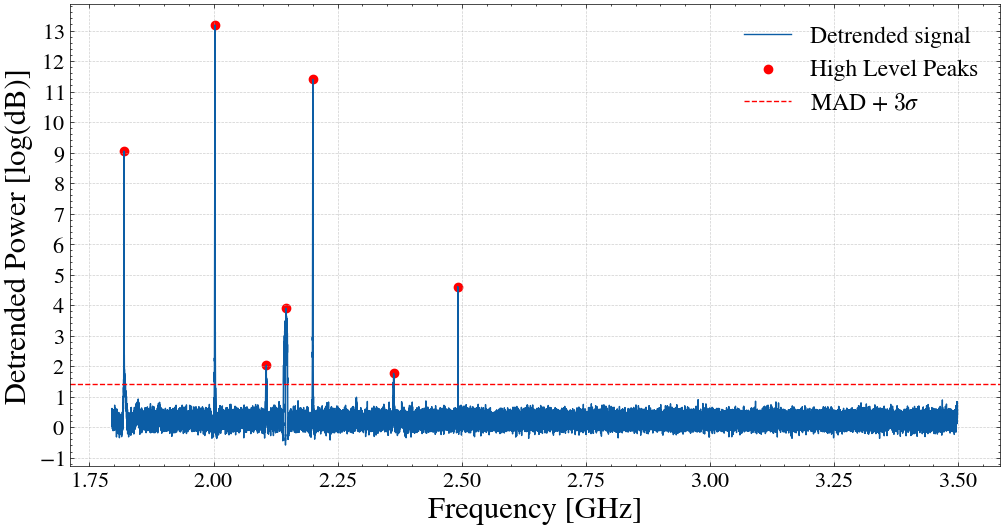

In [22]:
# plot for all time steps
results_all_times = process_all_times(frequency_ghz, spectrum_db, time_utc,sigma_value=sigma_value_high, time_step=15)



for res in results_all_times:

        # --- Print detected peak frequencies ---
    formatted_freqs = [f"{f:.4f}" for f in res['peak_freqs']]

    print(f"Peaks detected at [{time_utc[res['time_index']].strftime('%H:%M:%S')}]: {formatted_freqs} GHz")


    plt.figure(figsize=(12, 6))
    plt.plot(frequency_ghz, res['det_spec'], label=f'Detrended signal')
    plt.scatter(frequency_ghz[res['peaks']], res['det_spec'][res['peaks']], color='red', label='High Level Peaks')
    plt.axhline(y=res['threshold'], color='red', linestyle='--', label='MAD + $3σ$')
    #plt.title(f'High Level Peak detected at {res["time_label"]}', fontsize=19)
    plt.xlabel('Frequency [GHz]',fontsize=22)
    plt.ylabel('Detrended Power [log(dB)]',fontsize=22)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend(fontsize=17)

    yticks=np.arange(-1, 14, 1)
    plt.yticks(yticks)
    plt.yticks(fontsize=16)
    plt.xticks(fontsize=16)


    # create full path
    full_path = os.path.join(dirname, scan_name)
    # create the directory if they don't exist
    os.makedirs(full_path, exist_ok=True)

    plot_path = os.path.join(full_path, f'dynamic_spectrum{scan_name}.png')
    plt.savefig(plot_path, dpi=300)


    plt.show()

    break

# Frequency-of-occurrence analysis

-> From all detected peaks across time, determine which frequencies persist throughout the observation and show their occurrence percentage.

For  each detected peak:
* collect all peak frequencies acrros time;
* bin then info frequency bins;
* count how many time each bin appears;
* convert to percentage: P[%] = $ \frac{number of detections in bin}{number of time samples} x 100 $

In [23]:
# collet all peak frequencies 
all_peak_freqs = []
n_time_samples = len(results_all_times)

for res in results_all_times:
    all_peak_freqs.append(res['peak_freqs'])


# convert to Numpy array
all_peak_freqs = np.concatenate(
    [res['peak_freqs'] for res in results_all_times]
)  

# define the frequency bins for the histogram
freq_resolution = frequency_ghz[1] - frequency_ghz[0]
freq_bins = np.arange(frequency_ghz[0], frequency_ghz[-1] + freq_resolution, freq_resolution)

# compute histogram counts
counts, bin_edges = np.histogram(all_peak_freqs, bins=freq_bins)

# converts to percentage
high_level_percentages = (counts / n_time_samples) * 100
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2


In [24]:
# Define RFI bands (GHz) for MeerKAT S-band (1.75–3.5 GHz)
rfi_bands = {

"Cellular GSM Uplink": (1.71, 1.785),

"Cellular GSM Downlink": (1.805, 1.88),

"DECT Phones": (1.88, 1.90),

"UMTS Uplink": (1.92, 1.98),

"UMTS Downlink": (2.11, 2.17),

"Mobile Satellite": (2.00, 2.20),

"Space Research / EESS": (2.20, 2.29),

"IMT 2300 (4G/5G)": (2.30, 2.40),

"Wi-Fi / Bluetooth (ISM)": (2.40, 2.483),

"LTE / 5G (2600 band)": (2.50, 2.69),

"Air Traffic Radar": (2.70, 2.90),

"Weather Radar": (2.70, 3.00),

"Microwave Backhaul": (3.00, 3.30),

"5G NR (n78)": (3.30, 3.60)

}

colors = [
"#E41A1C","#377EB8","#4DAF4A","#984EA3","#FF7F00",
"#FFFF33","#A65628","#F781BF","#999999","#66C2A5",
"#FC8D62","#8DA0CB","#E78AC3","#A6D854"
]


transition_bands = {
    "Gap: GSM DL to GSM UL": (1.785, 1.805),
    "Gap: DECT to UMTS UL": (1.90, 1.92),
    "Gap: UMTS UL to MSS": (1.98, 2.00),
    "Gap: EESS to IMT-2300": (2.29, 2.30),
    "Gap: ISM to LTE 2600": (2.483, 2.50),
    "Gap: LTE 2600 to Radar": (2.69, 2.70),

    #"Overlap: MSS and UMTS DL": (2.11, 2.17),
    #"Overlap: Radar and Weather": (2.70, 2.90)
}

# combinne both bands
all_bands = dict(sorted(
    {**rfi_bands, **transition_bands}.items(),
    key=lambda item: item[1][0]  # sort by lower frequency
))

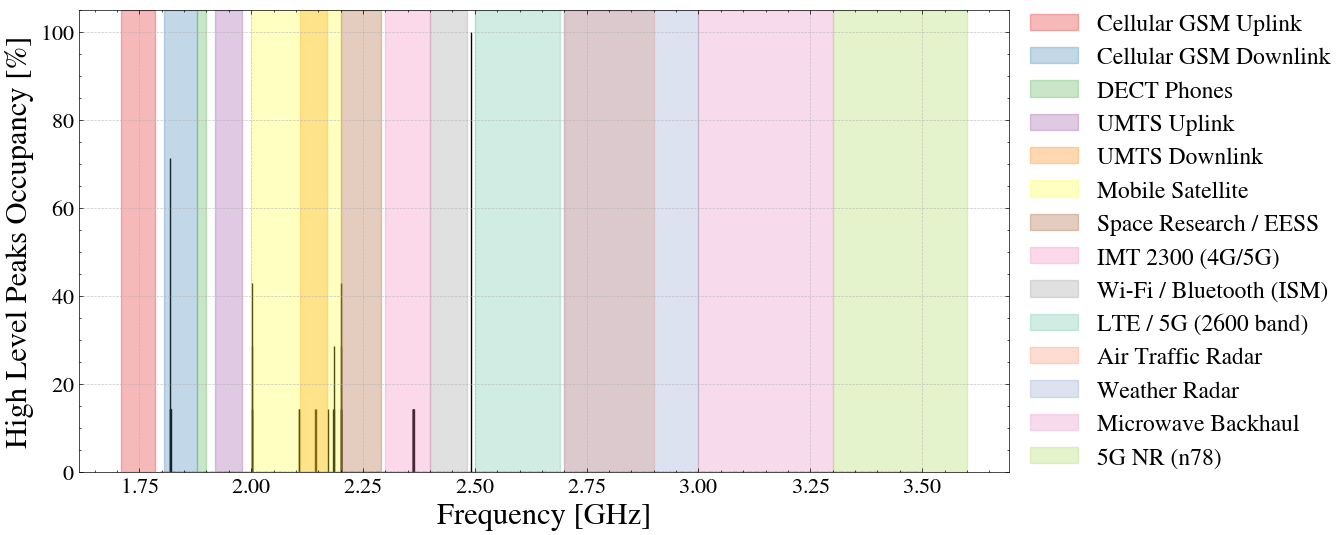

In [25]:


# plot the histogram of peak frequencies
plt.figure(figsize=(12, 6))
plt.bar(bin_centers, high_level_percentages, width=freq_resolution*0.8, align='center', edgecolor='black')

# --- Overlay RFI bands ---
for (label, (f_start, f_end)), color in zip(rfi_bands.items(), colors):
    plt.axvspan(f_start, f_end, color=color, alpha=0.3, label=label)

plt.xlabel('Frequency [GHz]', fontsize=22)
plt.ylabel('High Level Peaks Occupancy [%]', fontsize=22)
#plt.title('Distribution of Detected RFI Peak Frequencies', fontsize=18)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(fontsize=17, loc='center left', bbox_to_anchor=(1, 0.5))


#define the yticks size the same for all the plots
# yticks=np.arange(0, 0.5, 0.1)
# plt.yticks(yticks)
xticks=np.arange(1.75, 3.75, 0.25)
plt.xticks(xticks)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)


if to_save:
    #-----#---SAVE THE PLOT---#-----#
    # create full path
    full_path = os.path.join(dirname, scan_name)
    # create the directory if they don't exist
    os.makedirs(full_path, exist_ok=True)

    plot_png = os.path.join(full_path, f'HighLevelPeaks_Occupancy_{scan_name}.png')
    plot_pdf = os.path.join(full_path, f'HighLevelPeaks_Occupancy_{scan_name}.pdf')
    plt.savefig(plot_png, dpi=300, bbox_inches='tight')
    plt.savefig(plot_pdf, bbox_inches='tight')

The `2.483–2.500` GHz range in South Africa (and globally in ITU Region 1) is a small guard / transition band between the 2.4 GHz ISM band and the 2.6 GHz IMT mobile band. It is not heavily used by consumer wireless systems like Wi-Fi.

## Occupancy percentage per frequency channel

Identify only frequencies where peaks occurred

Print the frequency

Print its percentage over the full observation

In [26]:
occupancy = np.zeros(len(frequency))

for res in results_all_times:
    occupancy[res["peaks"]] += 1

percentage = (occupancy / n_time_samples) * 100
# extract olny frequencies where peaks occured
peak_channels = np.where(occupancy > 0)[0]
#print("Detected Peaks Across Full Observation:\n")

# Sorte by higest Persistence

sorted_indices = peak_channels[np.argsort(percentage[peak_channels])[::-1]]

print("High Level RFI Frequencies (sorted by occurrence):\n")

for ch in sorted_indices:
    print(f"{frequency[ch]:.6f} GHz  -->  {percentage[ch]:.2f} %")

High Level RFI Frequencies (sorted by occurrence):

2.492006 GHz  -->  100.00 %
1.819628 GHz  -->  71.43 %
2.002756 GHz  -->  42.86 %
2.199930 GHz  -->  42.86 %
2.184149 GHz  -->  28.57 %
2.199903 GHz  -->  28.57 %
2.002783 GHz  -->  28.57 %
2.362898 GHz  -->  14.29 %
2.362764 GHz  -->  14.29 %
2.362818 GHz  -->  14.29 %
2.199957 GHz  -->  14.29 %
2.199984 GHz  -->  14.29 %
2.362631 GHz  -->  14.29 %
2.362711 GHz  -->  14.29 %
2.362791 GHz  -->  14.29 %
2.170744 GHz  -->  14.29 %
2.184549 GHz  -->  14.29 %
2.183935 GHz  -->  14.29 %
2.106337 GHz  -->  14.29 %
2.141611 GHz  -->  14.29 %
2.145857 GHz  -->  14.29 %
2.106150 GHz  -->  14.29 %
2.002810 GHz  -->  14.29 %
2.002836 GHz  -->  14.29 %
1.819654 GHz  -->  14.29 %
1.819601 GHz  -->  14.29 %


# Flag the high level outlier from the data

For each detected peak frequency:

1. Find the closest index in the frequency array

2. From that index:

    * Walk LEFT until power drops below threshold

    * Walk RIGHT until power drops below threshold

3. Store:

    * start_freq

    * peak_freq

    * end_freq

4. Plot only that local region. This ensures:

    * Each peak is treated independently

    * No need for mask window

    * Works even when peaks are close together


Peaks detected at [14:58:43]: ['1.8196', '2.0028', '2.1063', '2.1459', '2.1999', '2.3627', '2.4920'] GHz

Outlier 1:
  Peak Frequency : 1.8196 GHz
  Peak Power     : 9.0500 dB
  Start Frequency: 1.8170 GHz
  End Frequency  : 1.8260 GHz
  Bandwidth      : 0.0090 GHz
  Corrupted Ch.  : 338 channels

Outlier 2:
  Peak Frequency : 2.0028 GHz
  Peak Power     : 13.1808 dB
  Start Frequency: 2.0008 GHz
  End Frequency  : 2.0048 GHz
  Bandwidth      : 0.0040 GHz
  Corrupted Ch.  : 150 channels

Outlier 3:
  Peak Frequency : 2.1063 GHz
  Peak Power     : 2.0321 dB
  Start Frequency: 2.1043 GHz
  End Frequency  : 2.1084 GHz
  Bandwidth      : 0.0041 GHz
  Corrupted Ch.  : 153 channels

Outlier 4:
  Peak Frequency : 2.1459 GHz
  Peak Power     : 3.8996 dB
  Start Frequency: 2.1452 GHz
  End Frequency  : 2.1495 GHz
  Bandwidth      : 0.0044 GHz
  Corrupted Ch.  : 163 channels

Outlier 5:
  Peak Frequency : 2.1999 GHz
  Peak Power     : 11.3992 dB
  Start Frequency: 2.1980 GHz
  End Frequency  : 

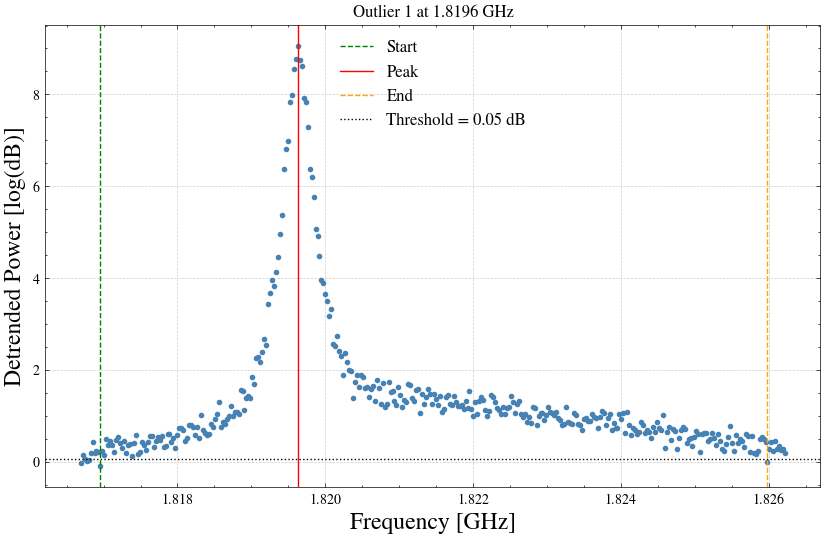

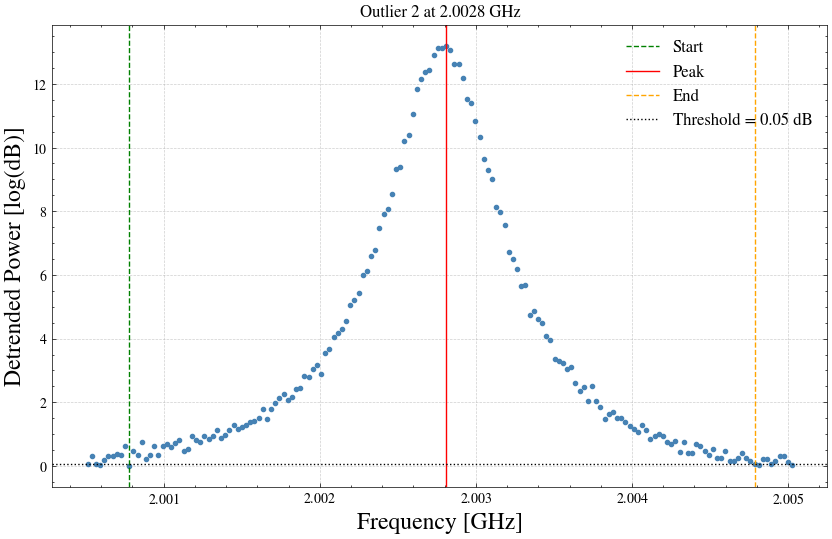

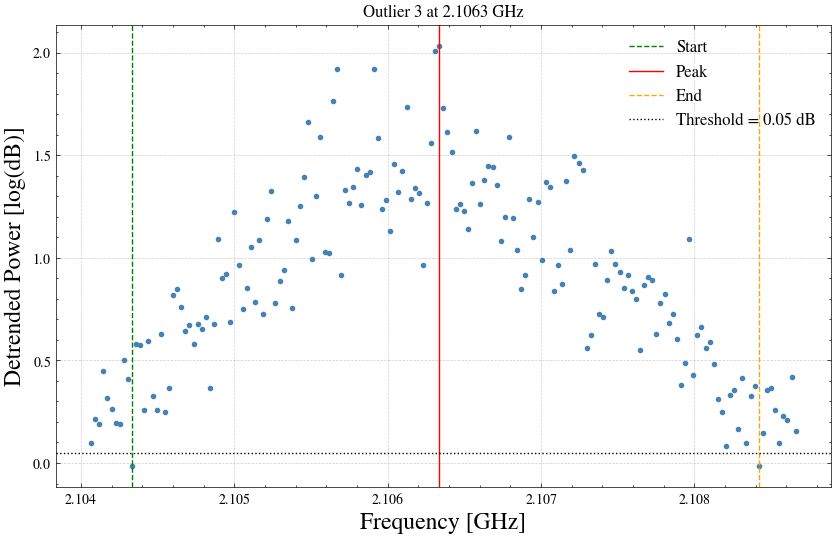

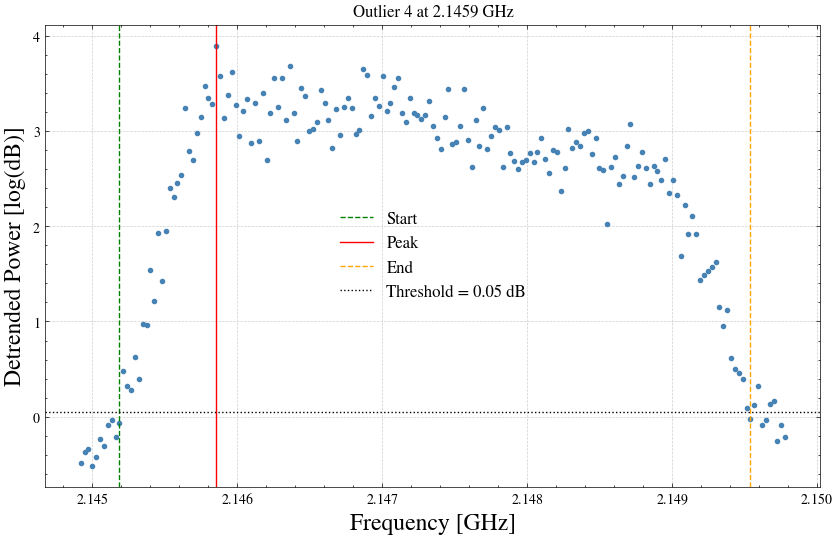

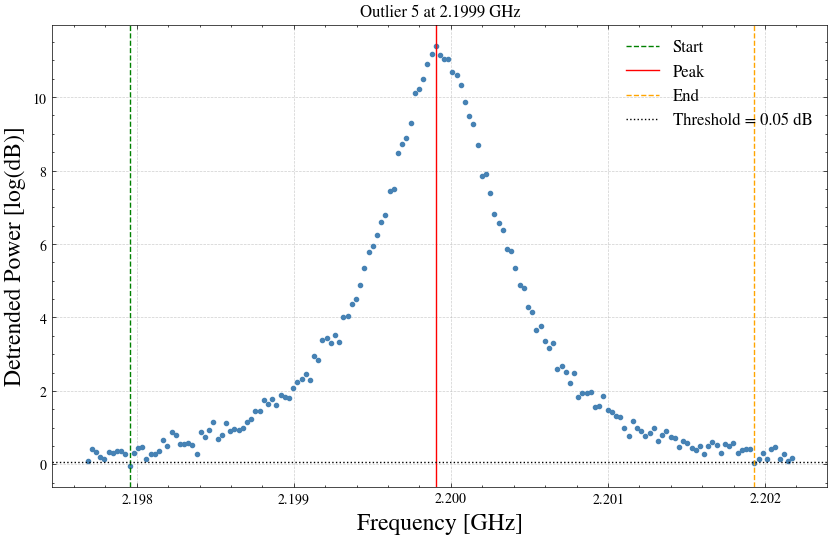

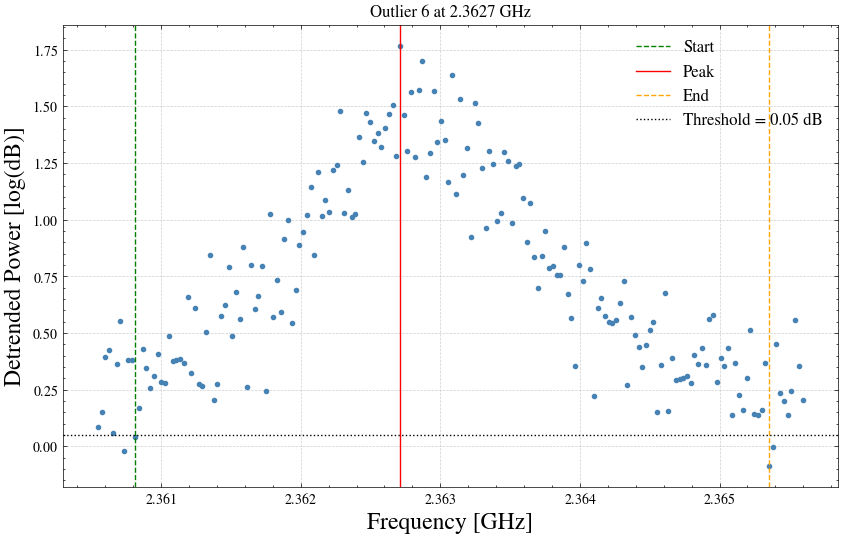

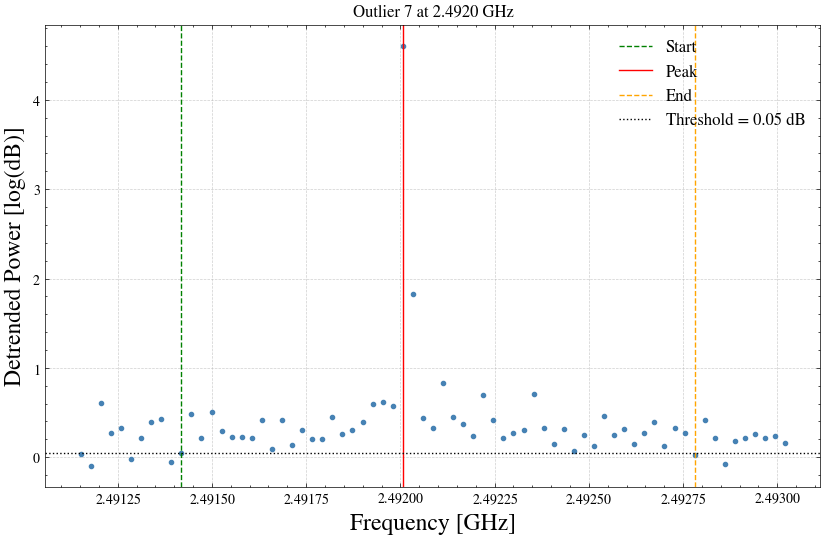

In [27]:


for res in results_all_times:

        # --- Print detected peak frequencies ---
    formatted_freqs = [f"{f:.4f}" for f in res['peak_freqs']]

    print(f"\nPeaks detected at [{time_utc[res['time_index']].strftime('%H:%M:%S')}]: {formatted_freqs} GHz")

    rest = res['det_spec']

    results_outliers = quantify_all_outliers(frequency, rest, res['peak_freqs'], plot=True)


    break

In [28]:
print("open figures:", plt.get_fignums())

open figures: []


In [29]:
band_rfi_stats = rfi_percentage_per_band_test(
    frequency_ghz,
    results_all_times,
    all_bands
)




Outlier 1:
  Peak Frequency : 1.8196 GHz
  Peak Power     : 9.0500 dB
  Start Frequency: 1.8170 GHz
  End Frequency  : 1.8260 GHz
  Bandwidth      : 0.0090 GHz
  Corrupted Ch.  : 338 channels

Outlier 2:
  Peak Frequency : 2.0028 GHz
  Peak Power     : 13.1808 dB
  Start Frequency: 2.0008 GHz
  End Frequency  : 2.0048 GHz
  Bandwidth      : 0.0040 GHz
  Corrupted Ch.  : 150 channels

Outlier 3:
  Peak Frequency : 2.1063 GHz
  Peak Power     : 2.0321 dB
  Start Frequency: 2.1043 GHz
  End Frequency  : 2.1084 GHz
  Bandwidth      : 0.0041 GHz
  Corrupted Ch.  : 153 channels

Outlier 4:
  Peak Frequency : 2.1459 GHz
  Peak Power     : 3.8996 dB
  Start Frequency: 2.1452 GHz
  End Frequency  : 2.1495 GHz
  Bandwidth      : 0.0044 GHz
  Corrupted Ch.  : 163 channels

Outlier 5:
  Peak Frequency : 2.1999 GHz
  Peak Power     : 11.3992 dB
  Start Frequency: 2.1980 GHz
  End Frequency  : 2.2019 GHz
  Bandwidth      : 0.0040 GHz
  Corrupted Ch.  : 149 channels

Outlier 6:
  Peak Frequency : 2.

/tmp/ipykernel_2711981/1720248067.py:303: RuntimeWarning: invalid value encountered in scalar divide
  percent = 100 * corrupted_points / total_band_points



Outlier 1:
  Peak Frequency : 1.8196 GHz
  Peak Power     : 8.7888 dB
  Start Frequency: 1.8181 GHz
  End Frequency  : 1.8264 GHz
  Bandwidth      : 0.0083 GHz
  Corrupted Ch.  : 312 channels

Outlier 2:
  Peak Frequency : 2.0028 GHz
  Peak Power     : 13.0741 dB
  Start Frequency: 2.0005 GHz
  End Frequency  : 2.0048 GHz
  Bandwidth      : 0.0043 GHz
  Corrupted Ch.  : 162 channels

Outlier 3:
  Peak Frequency : 2.1416 GHz
  Peak Power     : 2.2046 dB
  Start Frequency: 2.1402 GHz
  End Frequency  : 2.1444 GHz
  Bandwidth      : 0.0042 GHz
  Corrupted Ch.  : 158 channels

Outlier 4:
  Peak Frequency : 2.1841 GHz
  Peak Power     : 4.1665 dB
  Start Frequency: 2.1838 GHz
  End Frequency  : 2.1844 GHz
  Bandwidth      : 0.0006 GHz
  Corrupted Ch.  : 21 channels

Outlier 5:
  Peak Frequency : 2.2000 GHz
  Peak Power     : 11.2539 dB
  Start Frequency: 2.1979 GHz
  End Frequency  : 2.2019 GHz
  Bandwidth      : 0.0040 GHz
  Corrupted Ch.  : 149 channels

Outlier 6:
  Peak Frequency : 2.3

`For the future:`
`save the bands and the respect values, the date and time of the obsevation. To be able to analyse the average ocupacy fir the observation,`

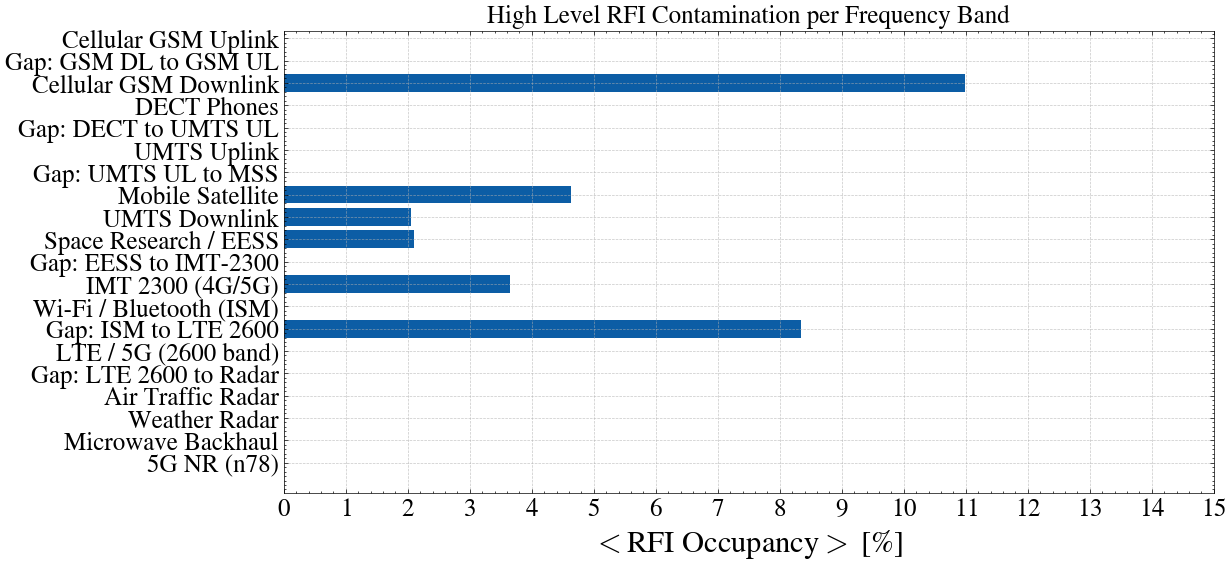

In [30]:
bands = list(band_rfi_stats.keys())
values = list(band_rfi_stats.values())

plt.figure(figsize=(12,6))
plt.barh(bands, values)


xticks=np.arange(0, 16, 1)
plt.xticks(xticks)

plt.xlabel("$<$RFI Occupancy$>$ [%] ", fontsize=22)
plt.yticks(fontsize=18)
plt.xticks(fontsize=18)

plt.title("High Level RFI Contamination per Frequency Band", fontsize=18)

plt.grid(True, linestyle='--', alpha=0.7)


plt.gca().invert_yaxis()  # first band at top, last at bottom

#to_save = True

if to_save:
    #-----#---SAVE THE PLOT---#-----#
    # create full path
    full_path = os.path.join(dirname, scan_name)
    # create the directory if they don't exist
    os.makedirs(full_path, exist_ok=True)

    plot_png = os.path.join(full_path, f'HighLevel_contamination_band_{scan_name}.png')
    plot_pdf = os.path.join(full_path, f'HighLevel_contamination_band_{scan_name}.pdf')
    plt.savefig(plot_png, dpi=300, bbox_inches='tight')
    plt.savefig(plot_pdf, bbox_inches='tight')

plt.show()

## Flag the high level RFI

For each time bin:

1. Use all detected (start_freq, end_freq) ranges

2. Flag those frequency channels in the power spectrum

3. Plot:

* Original spectrum

* Flagged spectrum (with RFI removed or masked)

This is exactly how RFI masks are constructed in radio astronomy.

In [31]:
# RFI mask

def build_rfi_mask(freq, results_outliers):
    """
    Create boolean mask for RFI contaminated channels.

    Returns:
        mask : True = flagged (RFI)
    """
    mask = np.zeros(len(freq), dtype=bool)

    for res in results_outliers:
        start = res["start_freq"]
        end = res["end_freq"]

        # Flag all frequencies inside range
        mask |= (freq >= start) & (freq <= end)

    return mask

``` For the low level RFI we changed the thresholt to MAD + 5STD- because it alow us to just peak the realy prominet values. The 3*STD was peaking some information of the the actual signal variation.```

Peaks detected at [14:58:43]: ['2.1437'] GHz


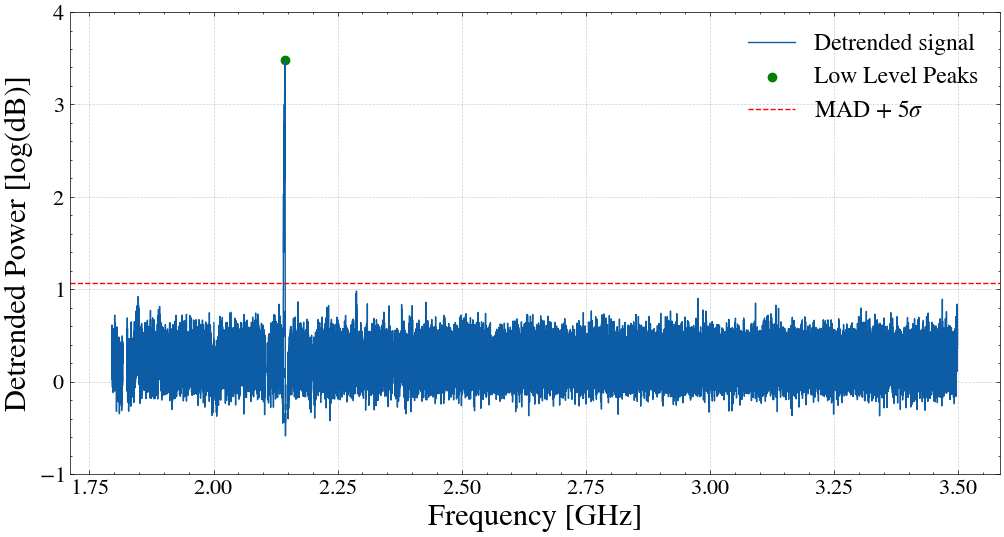

In [32]:
for i in itime_target:

    # 1) Detrend
    det_spec_itime = base_correction(frequency_ghz, spectrum_db[i, :])

    # 2) Build mask (must correspond to THIS time step)
    flag = build_rfi_mask(frequency_ghz, results_outliers)

    # 3) Apply mask (1D indexing!)
    spectrum_flagged = det_spec_itime.copy()
    spectrum_flagged[flag] = np.nan

    # 4) Detect peaks (ignore NaNs)
    det_spec = np.nan_to_num(spectrum_flagged, nan=0)

    sigma_value_low = 5 
    threshold = MAD(det_spec) + sigma_value_low * np.std(det_spec)


    peaks_low, properties = find_peaks(
        det_spec,
        height=threshold,
        prominence=1,
        distance=110
    )

    # 5) Plot
    plt.figure(figsize=(12, 6))
    plt.plot(frequency, spectrum_flagged, label='Detrended signal')
    plt.scatter(frequency[peaks_low], det_spec[peaks_low], 
                color='green', label='Low Level Peaks')

    plt.axhline(y=threshold, color='red', linestyle='--',
                label=f'MAD + {sigma_value_low}$σ$')

    #plt.title(f'Low Level Peaks at {time_utc[i].strftime("%H:%M:%S")}', fontsize=16)
    plt.xlabel('Frequency [GHz]', fontsize=22)
    plt.ylabel('Detrended Power [log(dB)]', fontsize=22)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend(fontsize=17)

    #define the yticks size the same for all the plots
    yticks=np.arange(-1, 5, 1)
    plt.yticks(yticks)
    plt.yticks(fontsize=16)
    plt.xticks(fontsize=16)


    formatted_freqs = [f"{f:.4f}" for f in frequency[peaks_low]]
    print(f"Peaks detected at [{time_utc[i].strftime('%H:%M:%S')}]: {formatted_freqs} GHz")

    plt.savefig('/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Detrending/SKAMPI_RFI_PIPELINE/low_level_peak_plot.png', dpi=300, bbox_inches='tight')
    plt.savefig('/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Detrending/SKAMPI_RFI_PIPELINE/low_level_peak_plot.pdf', dpi=300, bbox_inches='tight')


    plt.show()

    break

### Frequency Occupay for Low level

In [33]:
n_freq = len(frequency_ghz)
n_time = len(time_utc)

occupancy_counts = np.zeros(n_freq)

for idx, i in enumerate(itime_target):

    # 1) Detrend
    det_spec_itime = base_correction(frequency_ghz, spectrum_db[i, :])

    # 2) Mask high-level RFI
    flag = build_rfi_mask(frequency_ghz, results_outliers)

    spectrum_flagged = det_spec_itime.copy()
    spectrum_flagged[flag] = np.nan

    clean_spec = np.nan_to_num(spectrum_flagged, nan=0)

    threshold = MAD(clean_spec) + sigma_value_low * np.std(clean_spec)

    peaks_low, properties = find_peaks(
        clean_spec,
        height=threshold,
        prominence=1,
        distance=100
    )

    # ------------------------------------------------
    # NEW: Build mask for LOW-level peaks
    # ------------------------------------------------
    mask_low = np.zeros(n_freq, dtype=bool)

    for peak_idx in peaks_low:

        # walk left
        left = peak_idx
        while left > 0 and clean_spec[left] > 0.05:
            left -= 1

        # walk right
        right = peak_idx
        while right < n_freq-1 and clean_spec[right] > 0.05:
            right += 1

        mask_low[left:right+1] = True

    # accumulate occupancy
    occupancy_counts += mask_low.astype(int)

In [34]:
# convert to percentage
low_level_percentages = (occupancy_counts / n_time) * 100
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2


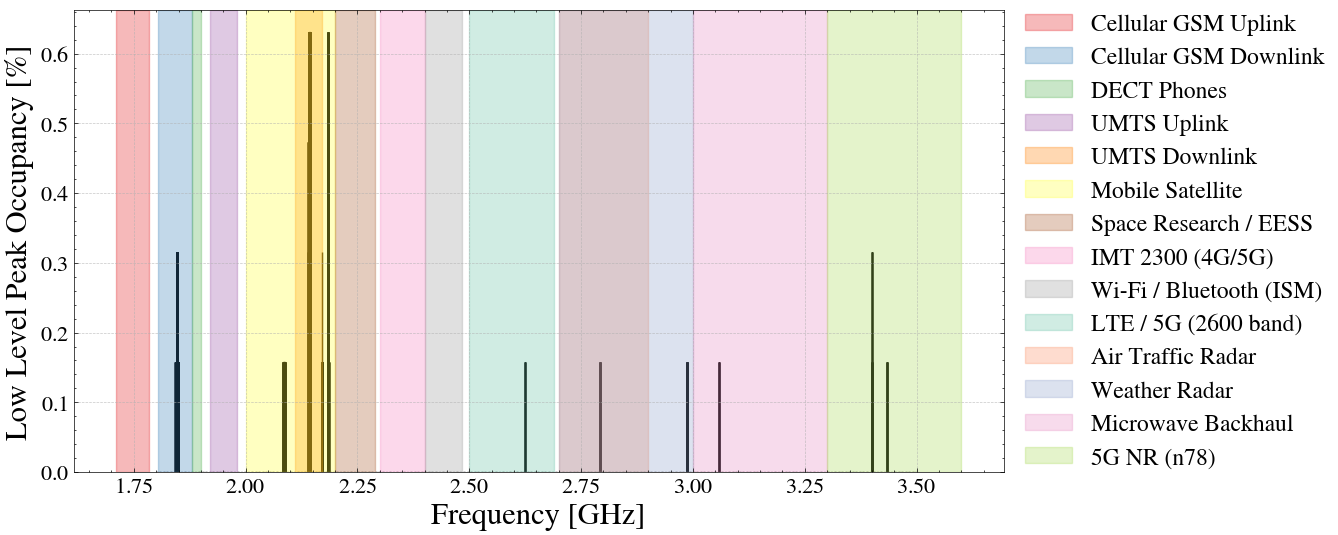

In [35]:

plt.figure(figsize=(12, 6))
plt.bar(frequency_ghz,
        low_level_percentages,
        width=freq_resolution * 0.5,
        align='center',
        edgecolor='black')

# --- Overlay RFI bands ---
for (label, (f_start, f_end)), color in zip(rfi_bands.items(), colors):
    plt.axvspan(f_start, f_end, color=color, alpha=0.3, label=label)

plt.xlabel('Frequency [GHz]', fontsize=22)
plt.ylabel('Low Level Peak Occupancy [%]', fontsize=22)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(fontsize=17, loc='center left', bbox_to_anchor=(1, 0.5))

#define the yticks size the same for all the plots
# yticks=np.arange(0, 0.5, 0.1)
# plt.yticks(yticks)
xticks=np.arange(1.75, 3.75, 0.25)
plt.xticks(xticks)
plt.yticks(fontsize=16)
plt.xticks(fontsize=16)

if to_save:
    #-----#---SAVE THE PLOT---#-----#
    # create full path
    full_path = os.path.join(dirname, scan_name)
    # create the directory if they don't exist
    os.makedirs(full_path, exist_ok=True)

    plot_png = os.path.join(full_path, f'LowLevelPeaks_Occupancy_{scan_name}.png')
    plot_pdf = os.path.join(full_path, f'LowLevelPeaks_Occupancy_{scan_name}.pdf')
    plt.savefig(plot_png, dpi=300, bbox_inches='tight')
    plt.savefig(plot_pdf, bbox_inches='tight')

plt.show()

The gap between `2.69 GHz and 2.70` GHz is deliberate and comes from spectrum regulation and interference management. Here’s why it exists:

1️- Adjacent Band Protection

2.50–2.69 GHz → LTE / 5G mobile broadband (IMT‑2600).

2.70–2.90 GHz → Air Traffic Control (ATC) and radar systems.

Regulators like ICASA create a small buffer (here ~10 MHz) to prevent harmful interference between:

High-power radar pulses (ATC radar)

LTE / 5G base stations and handsets

Without this buffer, radar pulses could desensitize mobile receivers, and mobile emissions could reduce radar sensitivity, which is safety-critical for aviation.

2️- Guard Bands in Radio Regulations

This 10 MHz “gap” is called a guard band.

It ensures that out-of-band emissions from LTE/5G and radar don’t overlap.

LTE/5G equipment can have spectral leakage of a few MHz; guard bands absorb this.

In [36]:
# extract olny frequencies where peaks occured
peak_channels = np.where(occupancy_percentage > 0)[0]
print("Detected Peaks Across Full Observation:\n")


#sorted by higest Persistence

sorted_indices = peak_channels[np.argsort(occupancy_percentage[peak_channels])[::-1]]

print("Persistent RFI Frequencies (sorted by occurrence):\n")

for ch in sorted_indices:
    print(f"{frequency[ch]:.6f} GHz  -->  {occupancy_percentage[ch]:.2f} %")


NameError: name 'occupancy_percentage' is not defined

In [ ]:
# percentage of the full range affected by RFI

band_results = {}

for band, (f_start, f_end) in rfi_bands.items():

    # find channels inside the band
    band_mask = (frequency_ghz >= f_start) & (frequency_ghz <= f_end)

    n_band_channels = np.sum(band_mask)

    if n_band_channels == 0:
        continue

    # channels in this band with detected peaks
    affected = np.sum((occupancy_percentage > 0) & band_mask)

    percent = (affected / n_band_channels) * 100

    band_results[band] = percent

# print results
for band, val in band_results.items():
    print(f"{band:30s}: {val:6.2f}% of band affected")

### Evaluate the low level RFI

In [ ]:
peak_freqs_low = frequency_ghz[peaks_low]

results_low_outliers = quantify_all_outliers(
    freq=frequency_ghz,
    power=det_spec,
    peak_freqs=peak_freqs_low,
    threshold=0.05,
    plot=True
)

In [ ]:
results_low_all_times = []

for res in results_all_times:

    # --- Extract information for this time bin ---
    time_label = res["time_label"]
    det_spec = res["det_spec"]
    peak_freqs = res["peak_freqs"]

    # --- Print detected peaks ---
    formatted_freqs = [f"{f:.4f}" for f in peak_freqs]

    print(f"\nPeaks detected at [{time_label}]: {formatted_freqs} GHz")

    # --- Quantify bandwidth affected by each peak ---
    results_low_outliers = quantify_all_outliers(
    freq=frequency_ghz,
    power=det_spec,
    peak_freqs=peak_freqs_low,
    threshold=0.05,
    plot=True
)

    # --- Store results for this time bin ---
    results_low_all_times.append({
        "time_label": time_label,
        "time_index": res["time_index"],
        "outliers": results_low_outliers
    })

    plt.show()

In [ ]:
results_low_outliers

From peak frequency extract the source band
From source band get the number of channels
take n_channels/band_channels

In [ ]:
band_rfi_stats_low = rfi_percentage_per_band_low(
    frequency_ghz,
    results_low_all_times,
    all_bands
)


In [ ]:
bands_low = list(band_rfi_stats_low.keys())
values_low= list(band_rfi_stats_low.values())

plt.figure(figsize=(12,6))
plt.barh(bands_low, values_low)

xticks=np.arange(0, 10.5, 0.5)
plt.xticks(xticks)

plt.xlabel("$<$RFI Occupancy$>$ [%] ", fontsize=22)
plt.yticks(fontsize=18)
plt.xticks(fontsize=16)
plt.title("Low Level RFI Contamination per Frequency Band", fontsize=18)

plt.grid(True, linestyle='--', alpha=0.7)
plt.gca().invert_yaxis()  # first band at top, last at bottom


#to_save = True

if to_save:
    #-----#---SAVE THE PLOT---#-----#
    # create full path
    full_path = os.path.join(dirname, scan_name)
    # create the directory if they don't exist
    os.makedirs(full_path, exist_ok=True)

    plot_png = os.path.join(full_path, f'LowLevel_contamination_band_{scan_name}.png')
    plot_pdf = os.path.join(full_path, f'LowLevel_contamination_band_{scan_name}.pdf')
    plt.savefig(plot_png, dpi=300, bbox_inches='tight')
    plt.savefig(plot_pdf, bbox_inches='tight')


plt.show()

### Plot the combination of the plot, high and low level temporal

In [ ]:

# Create two subplots sharing the x-axis
fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

# Data for each subplot
# High level comes from np.histogram (one value per bin -> bin_centers),
# low level is counted per channel (one value per channel -> frequency_ghz)
occupancy_data = [
    (bin_centers, high_level_percentages, 'High Level Peaks Occupancy [%]'),
    (frequency_ghz, low_level_percentages, 'Low Level Peak Occupancy [%]')
]

# Plot both occupancy distributions
for ax, (freqs, percentages, ylabel) in zip(axes, occupancy_data):

    # Histogram of peak frequencies
    ax.bar(
        freqs,
        percentages,
        width=freq_resolution * 0.8,
        align='center',
        edgecolor='black',
        label='_nolegend_'
    )

    # Overlay RFI bands
    for (label, (f_start, f_end)), color in zip(rfi_bands.items(), colors):
        ax.axvspan(
            f_start,
            f_end,
            color=color,
            alpha=0.3,
            label=label
        )

    # Axis formatting
    ax.set_ylabel(ylabel, fontsize=18)
    ax.grid(True, linestyle='--', alpha=0.7)
    ax.tick_params(axis='both', labelsize=16)

    # Consistent frequency ticks
    ax.set_xticks(np.arange(1.75, 3.75, 0.25))

# Shared x-axis label
axes[-1].set_xlabel('Frequency [GHz]', fontsize=22)

# Create one shared legend from the first subplot
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    fontsize=15,
    loc='center left',
    bbox_to_anchor=(0.88, 0.5)
)

# Leave space on the right for the shared legend
fig.tight_layout(rect=[0, 0, 0.85, 1])

# Optional: save the figure
# fig.savefig('RFI_Peak_Occupancy.png', dpi=300, bbox_inches='tight')
# fig.savefig('RFI_Peak_Occupancy.pdf', bbox_inches='tight')

plt.show()